## Task 2 - Face Recognition Module (FaceNet + Supabase)

### Libraries 

In [2]:
import os
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from facenet_pytorch import InceptionResnetV1
from dotenv import load_dotenv
import psycopg2
from pgvector.psycopg2 import register_vector

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

device: cuda


In [3]:
# we need train_split because its have the (file name)
base_path = "./celeba"
output_dir = os.path.join(base_path, "preprocessed_v2")

train_df = pd.read_csv(os.path.join(base_path, "train_split.csv"))
val_df = pd.read_csv(os.path.join(base_path, "val_split.csv"))

print("train images:", len(train_df))
print("val images:", len(val_df))

train images: 32597
val images: 6986


In [19]:
facenet_transform = transforms.Compose([
    transforms.Resize((160, 160)), #FaceNet always expects (160*160)
    transforms.ToTensor(), # conver image to tensor
    transforms.Lambda(lambda x: (x - 0.5) / 0.5)   # standard FaceNet input normalization
])

resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

### embedding function
This function is the heart of Task 2. Its job is to take one face image and convert it into a 512-dimensional embedding (a numerical fingerprint of the face).

In [20]:
def get_embedding(image_path, model, transform, device):
    img = Image.open(image_path).convert("RGB")
    tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = model(tensor)  #This is where FaceNet works (It only returns the embedding.)

    embedding = embedding.cpu().numpy().flatten()
    embedding = embedding / np.linalg.norm(embedding)  # L2 normalize
    return embedding

In [21]:
# quick check
sample_path = os.path.join(output_dir, train_df["file_name"].iloc[0])
sample_embedding = get_embedding(sample_path, resnet, facenet_transform, device)
print("embedding shape:", sample_embedding.shape)
print("embedding norm:", round(float(np.linalg.norm(sample_embedding)), 4))

embedding shape: (512,)
embedding norm: 1.0


### connect to the database

In [22]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)
db_url = os.getenv("SUPABASE_DB_URL")
print(repr(db_url))

'<redacted - set SUPABASE_DB_URL in .env>'


In [23]:
load_dotenv()
conn = psycopg2.connect(os.getenv("SUPABASE_DB_URL"))
register_vector(conn)
#cur is the messenger between python and the database 
#so we can make query 
cur = conn.cursor()

### enrollment flow - image -> embedding -> insert into face_embeddings

In [24]:
import psycopg2.extras # use it to insert many rows at ones 

batch_size = 50

# resume support :
cur.execute("select count(*) from face_embeddings") # SQL query to check how many face embedding already exist 
already_enrolled = cur.fetchone()[0] # fetchone() return one row so if the database contains 1500 row it will return (1500,)
print("already enrolled:", already_enrolled)


enroll_df = train_df.iloc[already_enrolled:].reset_index(drop=True)
print("remaining to enroll:", len(enroll_df))

start_time = time.time() # stores the currenct time (used to compute the speed)
rows_done = 0

for batch_start in range(0, len(enroll_df), batch_size):
    batch = enroll_df.iloc[batch_start:batch_start + batch_size]

    batch_values = [] # this list will store (identity, file name, embedding) for every 50 image
    for i, row in batch.iterrows(): # loops through a DataFrame one row at a time.
        img_path = os.path.join(output_dir, row["file_name"])
        embedding = get_embedding(img_path, resnet, facenet_transform, device)
        batch_values.append((str(row["identity"]), row["file_name"], embedding))

    psycopg2.extras.execute_values( # This inserts the whole batch instead of (50 INSERT queries) it performs (1 INSERT queries)
        cur,
        "insert into face_embeddings (identity, file_name, embedding) values %s",
        batch_values
    )
    conn.commit()

    rows_done += len(batch)
    if batch_start % (batch_size * 10) == 0 and batch_start > 0: # print progress every 10 batches 
        elapsed = time.time() - start_time # How long the program has been running.
        rate = rows_done / elapsed # Processing speed.
        eta_min = (len(enroll_df) - rows_done) / rate / 60 # calculate the Estimated Time Remaining.
        print(f"  {rows_done}/{len(enroll_df)}  |  {rate:.1f} img/s  |  ETA: {eta_min:.1f} min")

print()
print("enrollment done")

cur.execute("select count(*) from face_embeddings")
print("total rows in face_embeddings:", cur.fetchone()[0]) #fetchone: cursor method used to retrieve exactly one row (the next available row) from the result set

already enrolled: 32597
remaining to enroll: 0

enrollment done
total rows in face_embeddings: 32597


## verification flow
`<=>` is pgvector's cosine distance operator. `1 - distance` converts it back to similarity (1.0 = identical, 0.0 = unrelated), matching the scale we used with the local gallery.

In [25]:
def verify(image_path, model, transform, device, cur):
    query_embedding = get_embedding(image_path, model, transform, device) # This is the most important step. FaceNet does not compare images directly.
                                                                          # It converts every face into a numerical vector. (this vector become the query)
    # this is the query:
    cur.execute(
        """
        select identity, file_name, 1 - (embedding <=> %s) as similarity 
        from face_embeddings
        order by embedding <=> %s
        limit 1
        """,
        (query_embedding, query_embedding)
    )   

    identity, file_name, similarity = cur.fetchone()
    return identity, file_name, similarity

In [26]:
cur.execute("select count(*) from face_embeddings")
print("rows currently in DB:", cur.fetchone()[0])

rows currently in DB: 32597


### test 1: genuine match
pick an identity already enrolled, query with the same image.

In [27]:
enrolled_df = train_df.iloc[:32597].reset_index(drop=True)  # everything currently in the DB

# genuine match test
test_identity = enrolled_df["identity"].value_counts().index[0]
test_rows = enrolled_df[enrolled_df["identity"] == test_identity]

query_file = test_rows["file_name"].iloc[0]
query_path = os.path.join(output_dir, query_file)

matched_identity, matched_file, similarity = verify(query_path, resnet, facenet_transform, device, cur)

print("--- genuine test ---")
print("query identity (true):", test_identity)
print("matched identity:", matched_identity)
print("similarity score:", round(float(similarity), 4))
print("correct match:", str(matched_identity) == str(test_identity))

--- genuine test ---
query identity (true): 2937
matched identity: 2937
similarity score: 1.0
correct match: True


### test 2: impostor query
an identity that was never enrolled - similarity should score noticeably lower.

In [28]:
# real impostor test - use an identity from val_df, which has completely different identities than train_df
impostor_row = val_df.iloc[0]
impostor_path = os.path.join(output_dir, impostor_row["file_name"])

matched_identity, matched_file, similarity = verify(impostor_path, resnet, facenet_transform, device, cur)

print()
print("--- impostor test ---")
print("query identity (true, from val set - never enrolled):", impostor_row["identity"])
print("closest match found in gallery:", matched_identity)
print("similarity score:", round(float(similarity), 4))


--- impostor test ---
query identity (true, from val set - never enrolled): 2880
closest match found in gallery: 9792
similarity score: 0.5662


In [29]:
"""
cur.close()
conn.close()
print("connection closed")
"""

'\ncur.close()\nconn.close()\nprint("connection closed")\n'

In [30]:
threshold = 0.70

y_true = []
y_pred = []


genuine_df = train_df.sample(
    n=min(500, len(train_df)),
    random_state=42
).reset_index(drop=True)

for _, row in genuine_df.iterrows():

    query_path = os.path.join(output_dir, row["file_name"])

    predicted_identity, matched_file, similarity = verify(
        query_path,
        resnet,
        facenet_transform,
        device,
        cur
    )

    # Actual: genuine = 1
    y_true.append(1)

    # Prediction: accepted if similarity >= threshold
    y_pred.append(1 if float(similarity) >= threshold else 0)


# ------------------------------------------------------------
# 2. Impostor pairs
#    Query images from identities that are NOT enrolled
# ------------------------------------------------------------

impostor_df = val_df.sample(
    n=min(500, len(val_df)),
    random_state=42
).reset_index(drop=True)

for _, row in impostor_df.iterrows():

    query_path = os.path.join(output_dir, row["file_name"])

    predicted_identity, matched_file, similarity = verify(
        query_path,
        resnet,
        facenet_transform,
        device,
        cur
    )

    # Actual: impostor = 0
    y_true.append(0)

    # Prediction: accepted = 1, rejected = 0
    y_pred.append(1 if float(similarity) >= threshold else 0)


# ------------------------------------------------------------
# 3. Confusion Matrix
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()


# ------------------------------------------------------------
# 4. Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

# False Acceptance Rate
FAR = fp / (fp + tn) if (fp + tn) > 0 else 0

# False Rejection Rate
FRR = fn / (fn + tp) if (fn + tp) > 0 else 0


# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("=" * 50)
print("       FACE RECOGNITION EVALUATION")
print("=" * 50)

print(f"Threshold: {threshold}")

print("\nConfusion Matrix:")
print(f"TP (Genuine Accepted): {tp}")
print(f"TN (Impostor Rejected): {tn}")
print(f"FP (Impostor Accepted): {fp}")
print(f"FN (Genuine Rejected): {fn}")

print("\nEvaluation Metrics:")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.4f} ({f1 * 100:.2f}%)")
print(f"FAR       : {FAR:.4f} ({FAR * 100:.2f}%)")
print(f"FRR       : {FRR:.4f} ({FRR * 100:.2f}%)")

print("=" * 50)

       FACE RECOGNITION EVALUATION
Threshold: 0.7

Confusion Matrix:
TP (Genuine Accepted): 500
TN (Impostor Rejected): 404
FP (Impostor Accepted): 96
FN (Genuine Rejected): 0

Evaluation Metrics:
Accuracy  : 0.9040 (90.40%)
Precision : 0.8389 (83.89%)
Recall    : 1.0000 (100.00%)
F1 Score  : 0.9124 (91.24%)
FAR       : 0.1920 (19.20%)
FRR       : 0.0000 (0.00%)


### EVALUATION

In [31]:
# --- Week 3: Evaluation Metrics ---
import time
import random
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

val_df = pd.read_csv(os.path.join(base_path, "val_split.csv"))
print("val images:", len(val_df))
print("val identities:", val_df["identity"].nunique())

val images: 6986
val identities: 1401


This cell create two types of image pairs for evaluating the face recognition system 

In [32]:
random.seed(42) # generate random number with fixed seed

# genuine pairs - same identity, 2 images
genuine_pairs = []
grouped = val_df.groupby("identity")["file_name"].apply(list)
for identity, files in grouped.items():
    if len(files) >= 2:
        genuine_pairs.append((files[0], files[1], identity))

print("genuine pairs:", len(genuine_pairs))

# impostor pairs - different identities, same count as genuine
n_impostor = len(genuine_pairs)
all_files = val_df["file_name"].tolist()
all_identities = val_df["identity"].tolist()

impostor_pairs = []
attempts = 0
while len(impostor_pairs) < n_impostor and attempts < n_impostor * 20:
    i, j = random.sample(range(len(val_df)), 2)
    if all_identities[i] != all_identities[j]:
        impostor_pairs.append((all_files[i], all_files[j]))
    attempts += 1

print("impostor pairs:", len(impostor_pairs))

genuine pairs: 1401
impostor pairs: 1401


this cell calculates each image's embedding once and stores it in a cache.

In [33]:
# embed every image involved once, cache it
needed_files = set()
for f1, f2, _ in genuine_pairs:
    needed_files.add(f1)
    needed_files.add(f2)
for f1, f2 in impostor_pairs:
    needed_files.add(f1)
    needed_files.add(f2)

print("unique images to embed:", len(needed_files))

embedding_cache = {}
start_time = time.time()
for i, file_name in enumerate(needed_files):
    img_path = os.path.join(output_dir, file_name)
    embedding_cache[file_name] = get_embedding(img_path, resnet, facenet_transform, device)

    if i % 500 == 0 and i > 0:
        elapsed = time.time() - start_time
        print(f"  {i}/{len(needed_files)}  |  {i/elapsed:.1f} img/s")

print("done, cache size:", len(embedding_cache))

unique images to embed: 4248
  500/4248  |  7.2 img/s
  1000/4248  |  7.1 img/s
  1500/4248  |  6.6 img/s
  2000/4248  |  7.3 img/s
  2500/4248  |  7.9 img/s
  3000/4248  |  8.4 img/s
  3500/4248  |  8.6 img/s
  4000/4248  |  8.0 img/s
done, cache size: 4248


compares the embeddings and produces a similarity score for every pair.

In [36]:
# similarity per pair
similarities = []
labels = []  # 1 = genuine, 0 = impostor

for f1, f2, identity in genuine_pairs:
    sim = float(np.dot(embedding_cache[f1], embedding_cache[f2])) 
    similarities.append(sim)
    labels.append(1)

for f1, f2 in impostor_pairs:
    sim = float(np.dot(embedding_cache[f1], embedding_cache[f2]))
    similarities.append(sim)
    labels.append(0)

similarities = np.array(similarities)
labels = np.array(labels)

print("total pairs:", len(labels))
print("genuine similarity  - mean:", round(similarities[labels==1].mean(), 4))
print("impostor similarity - mean:", round(similarities[labels==0].mean(), 4))

total pairs: 2802
genuine similarity  - mean: 0.6335
impostor similarity - mean: 0.0457


In [37]:
# threshold sweep - find FAR/FRR crossover (EER)
thresholds = np.arange(0.0, 1.01, 0.01)
best_threshold = 0.5
best_diff = 1.0

print(f"{'threshold':>10} {'FAR':>8} {'FRR':>8}")
for t in thresholds:
    predictions = (similarities >= t).astype(int)

    fp = np.sum((predictions == 1) & (labels == 0))
    tn = np.sum((predictions == 0) & (labels == 0))
    fn = np.sum((predictions == 0) & (labels == 1))
    tp = np.sum((predictions == 1) & (labels == 1))

    far = fp / (fp + tn) if (fp + tn) > 0 else 0
    frr = fn / (fn + tp) if (fn + tp) > 0 else 0

    if abs(far - frr) < best_diff:
        best_diff = abs(far - frr)
        best_threshold = t

    if round(t * 100) % 10 == 0:
        print(f"{t:>10.2f} {far:>8.4f} {frr:>8.4f}")

print()
print("best threshold (EER point):", round(best_threshold, 2))

 threshold      FAR      FRR
      0.00   0.6146   0.0071
      0.10   0.3512   0.0186
      0.20   0.1492   0.0350
      0.30   0.0478   0.0607
      0.40   0.0107   0.0985
      0.50   0.0014   0.1813
      0.60   0.0000   0.3540
      0.70   0.0000   0.5767
      0.80   0.0000   0.8444
      0.90   0.0000   0.9857
      1.00   0.0000   1.0000

best threshold (EER point): 0.28


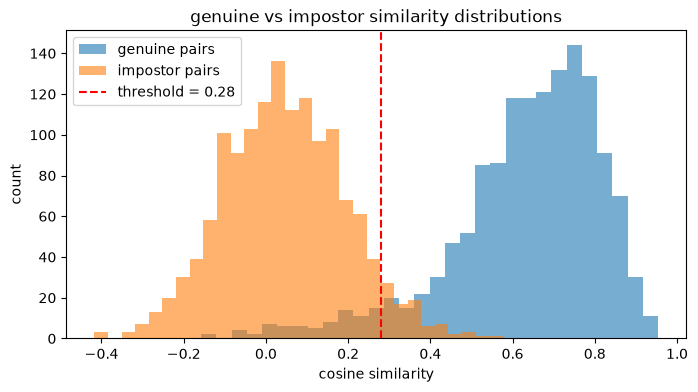

In [38]:
# plot distributions
plt.figure(figsize=(8, 4))
plt.hist(similarities[labels == 1], bins=30, alpha=0.6, label="genuine pairs")
plt.hist(similarities[labels == 0], bins=30, alpha=0.6, label="impostor pairs")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"threshold = {best_threshold:.2f}")
plt.xlabel("cosine similarity")
plt.ylabel("count")
plt.legend()
plt.title("genuine vs impostor similarity distributions")
plt.show()

In [39]:
# final metrics at chosen threshold
threshold = best_threshold
predictions = (similarities >= threshold).astype(int)

fp = np.sum((predictions == 1) & (labels == 0))
tn = np.sum((predictions == 0) & (labels == 0))
fn = np.sum((predictions == 0) & (labels == 1))
tp = np.sum((predictions == 1) & (labels == 1))

accuracy = accuracy_score(labels, predictions)
precision = precision_score(labels, predictions)
recall = recall_score(labels, predictions)
f1 = f1_score(labels, predictions)
far = fp / (fp + tn) if (fp + tn) > 0 else 0
frr = fn / (fn + tp) if (fn + tp) > 0 else 0

print("threshold used:", round(threshold, 2))
print()
print("accuracy: ", round(accuracy, 4))
print("precision:", round(precision, 4))
print("recall:   ", round(recall, 4))
print("f1 score: ", round(f1, 4))
print("FAR (false acceptance rate):", round(far, 4))
print("FRR (false rejection rate): ", round(frr, 4))
print()
print("confusion matrix:")
print("  TP:", tp, " FP:", fp)
print("  FN:", fn, " TN:", tn)

threshold used: 0.28

accuracy:  0.9436
precision: 0.9423
recall:    0.945
f1 score:  0.9437
FAR (false acceptance rate): 0.0578
FRR (false rejection rate):  0.055

confusion matrix:
  TP: 1324  FP: 81
  FN: 77  TN: 1320
